# Day 3: ตรวจจับเหตุการณ์ผิดปกติ (Episode Detection)

ต่อจาก `02_cleaning.ipynb` โดยใช้ `data/processed/hourly_merged.parquet`

**สิ่งที่ทำ**
1. สร้างค่าปกติ (baseline) แยกตามสถานี/ฤดู/ชั่วโมงของวัน
2. คำนวณ robust z-score (median + MAD)
3. ใช้เกณฑ์ค่าสัมบูรณ์จากมาตรฐาน PCD ควบคู่
4. รวมชั่วโมงผิดปกติติดกันเป็น "เหตุการณ์" (episode)
5. คำนวณ local increment (ค่าใกล้นิคม ลบ ค่าสถานีอ้างอิง)

**หมายเหตุ:** รันใหม่ใน Day 4 หลังเพิ่มสถานีอ้างอิงสำรอง 225690 (role `background_alt`) สถานีนี้ถูกคำนวณธงรายชั่วโมงไปด้วยเพื่อให้ Day 4 ใช้ตรวจผล แต่ตารางสรุปและเหตุการณ์ทั้งหมดใน notebook นี้ยังเป็นของ 3 สถานีหลัก (ตัวกรอง `MAIN`) ผลจึงเหมือนเดิมทุกตัว

ตารางสรุปและเหตุการณ์ใช้เฉพาะ 3 สถานีหลัก เพราะ 225690 เพิ่มมาเพื่อตรวจผล ไม่ควรขยับเกณฑ์ของสถานีหลัก

## 1. แบ่งฤดูและชั่วโมงของวัน

ใช้นิยามฤดูกาลของกรมอุตุนิยมวิทยา (ตัดที่กลางเดือน ไม่ปัดเป็นเดือนเต็ม)

| ฤดู | ช่วง |
|---|---|
| ร้อน (summer) | กลาง ก.พ. ถึง กลาง พ.ค. |
| ฝน (rainy) | กลาง พ.ค. ถึง กลาง ต.ค. |
| หนาว (winter) | กลาง ต.ค. ถึง กลาง ก.พ. |

In [1]:
import pandas as pd
import numpy as np
pd.set_option('display.width', 240)
pd.set_option('display.max_columns', None)

df = pd.read_parquet('../data/processed/hourly_merged.parquet')
df = df.sort_values(['station_id','datetime_utc']).reset_index(drop=True)

def season(ts):
    m, d = ts.month, ts.day
    if (m==2 and d>=15) or m in (3,4) or (m==5 and d<15):
        return 'summer'
    if (m==5 and d>=15) or m in (6,7,8,9) or (m==10 and d<15):
        return 'rainy'
    return 'winter'

df['hour_of_day'] = df['datetime_local'].dt.hour
df['season'] = df['datetime_local'].apply(season)

# สถานีอ้างอิงสำรอง 225690 (เพิ่มใน Day 4) คำนวณธงรายชั่วโมงไปด้วย เพื่อให้ Day 4 ใช้ตรวจผล
# แต่ตารางสรุปและการสร้างเหตุการณ์ของ Day 3 ใช้เฉพาะ 3 สถานีหลัก
MAIN = df['role'] != 'background_alt'

print('แบ่งฤดูตามนิยามกรมอุตุนิยมวิทยา:')
print(df.loc[MAIN, 'season'].value_counts().to_string())
print()
display(df.loc[MAIN, ['datetime_local','hour_of_day','season']].sample(5, random_state=1))


แบ่งฤดูตามนิยามกรมอุตุนิยมวิทยา:
season
rainy     56628
winter    36572
summer    35443



,datetime_local,hour_of_day,season
116694,2024-05-27 02:00:00+07:00,2,rainy
18826,2019-04-19 05:00:00+07:00,5,summer
20842,2019-08-14 15:00:00+07:00,15,rainy
61263,2026-09-09 06:00:00+07:00,6,rainy
120956,2025-03-03 08:00:00+07:00,8,summer


## 2. ปัญหาที่ต้องแก้ก่อนคำนวณ z-score: MAD = 0

robust z-score ใช้สูตร `z = 0.6745 * (x - median) / MAD` ซึ่งจะ**หารด้วยศูนย์**ถ้า MAD เป็น 0

เกิดกับ SO₂ เพราะหลายกลุ่มมีค่า 0.000 มากกว่าครึ่ง (อากาศสะอาดจนต่ำกว่าขีดที่เครื่องวัดได้) ทำให้ทั้ง median และ MAD เป็น 0

In [2]:
POLLUTANTS = ['so2','no2','co','o3','pm10','pm25']
RESOLUTION = {'so2':0.001, 'no2':0.001, 'co':0.01, 'o3':0.001, 'pm10':1.0, 'pm25':0.1}

g = df.groupby(['station_id','season','hour_of_day'])
rows = []
for p in POLLUTANTS:
    mad_raw = g[p].transform(lambda s: (s - s.median()).abs().median())
    n_zero = ((mad_raw == 0) & MAIN).sum()
    rows.append({'สาร': p,
                 'ความละเอียดเครื่องวัด': RESOLUTION[p],
                 'ชม.ที่ MAD=0': int(n_zero),
                 '% ของข้อมูล': round(100*n_zero/df.loc[MAIN, p].notna().sum(), 1)})

print('ปัญหา MAD = 0 (จะทำให้หารด้วยศูนย์):')
display(pd.DataFrame(rows))


ปัญหา MAD = 0 (จะทำให้หารด้วยศูนย์):


,สาร,ความละเอียดเครื่องวัด,ชม.ที่ MAD=0,% ของข้อมูล
0,so2,0.001,26773,30.0
1,no2,0.001,0,0.0
2,co,0.010,0,0.0
3,o3,0.001,0,0.0
4,pm10,1.000,0,0.0
5,pm25,0.100,0,0.0


**วิธีแก้: ใส่พื้น (floor) ให้ MAD ไม่ต่ำกว่าความละเอียดของเครื่องวัด**

```
MAD_ที่ใช้ = max(MAD, ความละเอียดเครื่องวัด)
```

เหตุผล: เครื่องวัดอ่านค่าได้ละเอียดสุดขั้นละ 0.001 ppm (ตรวจจากข้อมูลจริง) ดังนั้นการกระจายของข้อมูลจะเล็กกว่านั้นไม่ได้ในทางกายภาพ ค่า floor นี้จึงมีที่มา ไม่ใช่ตัวเลขที่ตั้งลอย ๆ

ถ้าปล่อยเป็นค่าว่าง 23.4% ของข้อมูล SO₂ จะตรวจจับไม่ได้เลย (ค่าสูงสุดในกลุ่มนั้นคือ 0.204 ppm ซึ่งไม่ถึงมาตรฐาน PCD)

## 3. คำนวณ robust z-score

ใช้ **z ≥ 5** เพราะข้อมูลมลพิษมีหางขวายาวกว่าการแจกแจงปกติมาก ผลคือ PM2.5 ถูก flag ราว 1% ของชั่วโมงที่วัด

ใช้เกณฑ์เดียวกันทุกสาร เพื่อไม่ให้เป็นการจูนรายสารโดยไม่มีอะไรรองรับ ส่วนการแยกรายสารมาจากมาตรฐาน PCD ในหัวข้อ 4 ซึ่งมีเหตุผลด้านสุขภาพรองรับ

In [3]:
Z_THRESHOLD = 5

for p in POLLUTANTS:
    med = g[p].transform('median')
    mad_raw = g[p].transform(lambda s: (s - s.median()).abs().median())
    mad_eff = mad_raw.clip(lower=RESOLUTION[p])      # ใส่พื้นกัน MAD=0
    df[f'{p}_z'] = 0.6745 * (df[p] - med) / mad_eff
    df[f'{p}_z_flag'] = df[f'{p}_z'] >= Z_THRESHOLD

print(f'อัตราการ flag ด้วย z >= {Z_THRESHOLD} แยกตามสถานี (SO2):')
for sid, sub in df[df.so2.notna()].groupby('station_id'):
    role = sub['role'].iloc[0]
    n_flag = sub['so2_z_flag'].sum()
    print(f'   {sid} ({role}): {n_flag}/{len(sub)} = {100*n_flag/len(sub):.2f}%')


อัตราการ flag ด้วย z >= 5 แยกตามสถานี (SO2):
   717 (background): 425/47595 = 0.89%
   7846 (near): 935/20340 = 4.60%
   225611 (near): 2133/21352 = 9.99%
   225690 (background_alt): 33/8051 = 0.41%


สถานีใกล้นิคมที่สุด (225611) มีอัตราผิดปกติสูงกว่าสถานีอ้างอิงราว 11 เท่า

ย้ำว่า baseline คำนวณแยกต่อสถานี ดังนั้นแต่ละสถานีถูกเทียบกับค่าปกติของตัวเอง ตัวเลขนี้จึงหมายถึง "ค่าแกว่งผิดไปจากนิสัยปกติของสถานีนั้นบ่อยแค่ไหน" ไม่ใช่ "สกปรกกว่ากี่เท่า"

ตรวจทานอีกทางด้วยค่าสัมบูรณ์ (ไม่อิง baseline): สัดส่วนชั่วโมงที่ SO₂ ≥ 0.01 ppm คือ 0.70% / 5.30% / 16.58% (717 / 7846 / 225611) ซึ่งเรียงลำดับตรงกัน ยืนยันว่าไม่ใช่ภาพลวงจากวิธีคำนวณ

สถานีอ้างอิงสำรอง 225690 (เพิ่มใน Day 4) มีอัตรา 0.41% ต่ำที่สุดในทุกสถานี สอดคล้องกับที่มันมีพื้นที่อุตสาหกรรมรอบตัวน้อยกว่า 717 มาก

## 4. เกณฑ์ค่าสัมบูรณ์จากมาตรฐาน PCD

**ที่มา:** ประกาศคณะกรรมการสิ่งแวดล้อมแห่งชาติ เรื่อง กำหนดมาตรฐานคุณภาพอากาศในบรรยากาศโดยทั่วไป พ.ศ. 2569 (ราชกิจจานุเบกษา เล่ม ๑๔๓ ตอนพิเศษ ๒๐ ง, ๒๑ มกราคม ๒๕๖๙) ตรวจสอบจากเอกสารต้นฉบับโดยตรง

| สาร | ช่วงเวลา | ค่ามาตรฐาน |
|---|---|---|
| SO₂ | 1 ชม. / 24 ชม. | 100 / 50 ppb |
| NO₂ | 1 ชม. / 1 ปี | 120 / 30 ppb |
| CO | 1 ชม. / 8 ชม. | 30 / 9 ppm |
| O₃ | 1 ชม. / 8 ชม. | 100 / 70 ppb |
| PM10 | 24 ชม. / 1 ปี | 100 / 50 µg/m³ |
| PM2.5 | 24 ชม. / 1 ปี | 37.5 / 15 µg/m³ |

หมายเหตุ: มาตรฐานนี้เข้มขึ้นกว่าฉบับเดิมมาก (SO₂ 1 ชม. เดิม 0.3 ppm ตามประกาศฉบับที่ 21 พ.ศ. 2544 เหลือ 0.1 ppm) ซึ่งมีผลต่อจำนวนเหตุการณ์ที่ตรวจพบอย่างมีนัยสำคัญ

**เหตุการณ์ = เข้าเกณฑ์ใดเกณฑ์หนึ่ง (z-score หรือ ค่าสัมบูรณ์)**

In [4]:
STD_1H  = {'so2':0.100, 'no2':0.120, 'o3':0.100, 'co':30.0}   # ppm
STD_24H = {'pm25':37.5, 'pm10':100.0}                          # ug/m3

for p, thr in STD_1H.items():
    df[f'{p}_abs_flag'] = df[p] >= thr

for p, thr in STD_24H.items():
    parts = []
    for sid, sub in df.groupby('station_id'):
        r = sub.set_index('datetime_utc')[p].rolling('24h', min_periods=18).mean()
        parts.append(pd.Series(r.values, index=sub.index))
    df[f'{p}_roll24'] = pd.concat(parts).sort_index()
    df[f'{p}_abs_flag'] = df[f'{p}_roll24'] >= thr

for p in POLLUTANTS:
    df[f'{p}_episode_flag'] = df[f'{p}_z_flag'].fillna(False) | df[f'{p}_abs_flag'].fillna(False)

print('เปรียบเทียบว่าเกณฑ์ไหนจับได้บ้าง:')
rows = []
for p in POLLUTANTS:
    zf = df.loc[MAIN, f'{p}_z_flag'].fillna(False)
    af = df.loc[MAIN, f'{p}_abs_flag'].fillna(False)
    rows.append({'สาร':p, 'รวม':int((zf|af).sum()),
                 'เฉพาะ z':int((zf & ~af).sum()),
                 'เฉพาะ abs':int((af & ~zf).sum()),
                 'ทั้งคู่':int((zf & af).sum())})
display(pd.DataFrame(rows))


เปรียบเทียบว่าเกณฑ์ไหนจับได้บ้าง:


,สาร,รวม,เฉพาะ z,เฉพาะ abs,ทั้งคู่
0,so2,3493,3449,0,44
1,no2,526,517,0,9
2,co,277,277,0,0
3,o3,1237,1128,34,75
4,pm10,760,179,494,87
5,pm25,5220,371,4445,404


## 5. ผลสำคัญ: ทำไมต้องใช้สองเกณฑ์ควบคู่

จากตารางข้างบน **PM2.5 มี 4,445 ชั่วโมงที่เกินมาตรฐาน PCD แต่ z-score มองไม่เห็นเลย** (z จับได้ลำพังเพียง 371 ชั่วโมง)

ดูว่าชั่วโมงเหล่านี้อยู่ในฤดูไหน

In [5]:
abs_only = df[MAIN & df['pm25_abs_flag'].fillna(False) & ~df['pm25_z_flag'].fillna(False)]

cmp = pd.DataFrame({
    'ชม.ที่ z มองไม่เห็น': abs_only['season'].value_counts(),
    'ข้อมูลทั้งหมด': df.loc[MAIN, 'season'].value_counts(),
})
cmp['% ที่ z พลาด'] = (100*cmp['ชม.ที่ z มองไม่เห็น']/cmp['ชม.ที่ z มองไม่เห็น'].sum()).round(1)
cmp['% ของข้อมูลทั้งหมด'] = (100*cmp['ข้อมูลทั้งหมด']/cmp['ข้อมูลทั้งหมด'].sum()).round(1)

print('PM2.5: ชั่วโมงที่เกินมาตรฐาน PCD แต่ z-score มองไม่เห็น')
display(cmp)
print('ตัวอย่าง:')
display(abs_only.sample(5, random_state=1)[['station_id','season','pm25','pm25_z','pm25_roll24']])


PM2.5: ชั่วโมงที่เกินมาตรฐาน PCD แต่ z-score มองไม่เห็น


,ชม.ที่ z มองไม่เห็น,ข้อมูลทั้งหมด,% ที่ z พลาด,% ของข้อมูลทั้งหมด
season,,,,
rainy,31,56628,0.7,44.0
summer,1552,35443,34.9,27.6
winter,2862,36572,64.4,28.4


ตัวอย่าง:


,station_id,season,pm25,pm25_z,pm25_roll24
114558,225611,winter,57.1,3.093064,49.233333
94803,7846,summer,37.2,2.243745,38.100000
32083,717,winter,47.0,2.192125,47.375000
81960,7846,winter,37.8,1.044652,40.650000
44911,717,summer,58.3,4.435901,58.531579


ฤดูหนาวกับฤดูร้อนรวมกันคิดเป็น **99.3%** ของชั่วโมงที่ z-score พลาด ทั้งที่สองฤดูนี้รวมกันมีแค่ 56% ของข้อมูลทั้งหมด ตรงกับฤดูหมอกควันของไทย (พ.ย. ถึง เม.ย.)

ดูตัวอย่างแถวแรก: PM2.5 = 57.1 µg/m³ (เกินมาตรฐาน 37.5 เกือบเท่าตัว) แต่ z-score ได้แค่ 3.09 เพราะฤดูหนาวที่สถานีนั้น "ปกติ" ก็สูงอยู่แล้ว median ของกลุ่มจึงถูกดันขึ้นจนค่า 57 ดูไม่ผิดปกติ

**จึงต้องใช้เกณฑ์ค่าสัมบูรณ์ควบคู่กับ z-score**

## 6. Local increment

`local increment = ค่าสถานีใกล้นิคม − ค่าสถานีอ้างอิง` ที่เวลาเดียวกัน

ยิ่งค่าสูง ยิ่งบ่งชี้ว่ามลพิษนั้นมาจากแหล่งในพื้นที่ ไม่ใช่สภาพอากาศของทั้งภูมิภาค (นี่คือเหตุผลที่ Day 2 ต้อง pivot เป็น wide format ไว้ก่อน)

In [6]:
control = df[df.role=='background'].set_index('datetime_utc')[POLLUTANTS]
control.columns = [f'{p}_ctrl' for p in POLLUTANTS]

near = df[df.role=='near'].join(control, on='datetime_utc')
for p in POLLUTANTS:
    near[f'{p}_increment'] = near[p] - near[f'{p}_ctrl']

print('local increment = ค่าสถานีใกล้นิคม - ค่าสถานีอ้างอิง (เวลาเดียวกัน)')
display(near[near.station_id==225611][['datetime_local','so2','so2_ctrl','so2_increment']].dropna().head(5))
print('ค่าเฉลี่ย increment แยกตามสถานี:')
display(near.groupby('station_id')[[f'{p}_increment' for p in ['so2','pm25','no2']]].mean().round(4))


local increment = ค่าสถานีใกล้นิคม - ค่าสถานีอ้างอิง (เวลาเดียวกัน)


,datetime_local,so2,so2_ctrl,so2_increment
98883,2021-04-30 02:00:00+07:00,0.002,0.000,0.002
98884,2021-04-30 04:00:00+07:00,0.001,0.000,0.001
98885,2021-04-30 05:00:00+07:00,0.001,0.000,0.001
98886,2021-04-30 06:00:00+07:00,0.000,0.000,0.000
98887,2021-04-30 07:00:00+07:00,0.000,0.001,-0.001


ค่าเฉลี่ย increment แยกตามสถานี:


,so2_increment,pm25_increment,no2_increment
station_id,,,
7846,0.0016,0.0299,0.0024
225611,0.0028,3.1687,0.0066


สถานี 225611 (ใกล้นิคมที่สุด 4.5 กม.) มี increment สูงกว่า 7846 (5.8 กม.) ในทุกสาร โดยเฉพาะ PM2.5 ที่ต่างกันมาก (3.17 เทียบกับ 0.03 µg/m³) ซึ่งสอดคล้องกับระยะทางจากแหล่ง

## 7. รวมชั่วโมงผิดปกติติดกันเป็นเหตุการณ์ (episode)

ชั่วโมงที่ flag ติดกันในสถานีเดียวกันและสารเดียวกัน นับเป็น 1 เหตุการณ์ บันทึกเวลาเริ่ม/จบ ความยาว ค่าสูงสุด และ z สูงสุด

In [7]:
def build_episodes(frame, p):
    f = frame.sort_values(['station_id', 'datetime_utc']).copy()
    flag = f[f'{p}_episode_flag'].fillna(False)
    # เลขรอบเพิ่มทุกครั้งที่เจอชั่วโมงปกติ ชั่วโมงผิดปกติที่ติดกันจึงได้เลขเดียวกัน
    f['_run'] = (~flag).cumsum()
    ep = (f[flag].groupby(['station_id', '_run'])
          .agg(role=('role', 'first'),
               start_utc=('datetime_utc', 'min'), end_utc=('datetime_utc', 'max'),
               duration_hours=('datetime_utc', 'size'), peak_value=(p, 'max'),
               peak_z=(f'{p}_z', 'max'), triggered_by_abs=(f'{p}_abs_flag', 'any'))
          .reset_index().drop(columns='_run'))
    ep.insert(2, 'pollutant', p)
    return ep

# สร้างเหตุการณ์เฉพาะ 3 สถานีหลัก (MAIN จากหัวข้อ 1)
# ถ้ารวมเข้ามา p99 ของความยาวเหตุการณ์ในหัวข้อ 8 จะขยับไปด้วย
episodes = pd.concat([build_episodes(df[MAIN], p) for p in POLLUTANTS], ignore_index=True)

summary = (episodes.groupby('pollutant')
           .agg(จำนวนเหตุการณ์=('duration_hours', 'size'),
                ความยาวมัธยฐาน=('duration_hours', 'median'),
                ความยาวเฉลี่ย=('duration_hours', 'mean'),
                ความยาวสูงสุด=('duration_hours', 'max'))
           .round(1))
summary

,จํานวนเหตุการณ์,ความยาวมัธยฐาน,ความยาวเฉลี่ย,ความยาวสูงสุด
pollutant,,,,
co,66,1.5,4.2,78
no2,271,1.0,1.9,39
o3,513,1.0,2.4,36
pm10,55,9.0,13.8,65
pm25,188,14.0,27.8,295
so2,1358,1.0,2.6,385


ความยาวเหตุการณ์ของแต่ละสารต่างกันชัดเจน

| สาร | ความยาวมัธยฐาน | ตีความ |
|---|---|---|
| SO₂ / NO₂ / O₃ | 1 ชั่วโมง | พุ่งแล้วจบเร็ว สอดคล้องกับกลุ่มควันจากแหล่งจุด |
| PM10 | 9 ชั่วโมง | |
| PM2.5 | 14 ชั่วโมง | ค่อย ๆ สะสม สอดคล้องกับหมอกควันภูมิภาค |

ผลนี้ได้มาก่อนใช้ข้อมูลลมเลย

## 8. ติดป้ายเหตุการณ์ที่ตรวจสอบไม่ได้ (unverifiable)

พบเหตุการณ์ SO₂ ยาว 385 ชั่วโมง (16 วัน) ที่สถานี 225611 ซึ่งผิดธรรมชาติมาก (ค่ามัธยฐานของเหตุการณ์ SO₂ ทั่วไปคือ 1 ชั่วโมง) ดูกราฟรายวันแล้วพบว่าค่ากระโดดจาก ~0.003 ไป ~0.077 แล้วนิ่งอยู่อย่างนั้น 33 วัน ซึ่งเข้าลักษณะ **เซนเซอร์ดริฟต์** มากกว่ามลพิษจริง

**แต่เราพิสูจน์ไม่ได้** เพราะช่วงเวลานั้นไม่มีสถานีอื่นวัด SO₂ เลย จึงไม่มีทางตรวจสอบยืนยัน

**วิธีที่เลือก: ติดป้ายว่าตรวจสอบไม่ได้ ไม่ลบทิ้ง** โดยใช้กฎที่คำนวณได้และใช้ซ้ำได้:

> เหตุการณ์ถูกติดป้าย `unverifiable` เมื่อ **ยาวเกิน p99 ของสารนั้น** และ **ไม่มีสถานีอื่นวัดสารเดียวกันในช่วงเวลานั้น** (ตรวจสอบข้ามสถานีไม่ได้)

In [8]:
p99 = episodes.groupby('pollutant')['duration_hours'].quantile(0.99)
print('p99 ความยาวเหตุการณ์ของแต่ละสาร (คำนวณจากข้อมูลเอง):')
print(p99.round(1).to_string())

def can_corroborate(row):
    """มีสถานีอื่นวัดสารเดียวกันในช่วงเวลานั้นหรือไม่"""
    w = df[(df.datetime_utc >= row.start_utc) & (df.datetime_utc <= row.end_utc) &
           (df.station_id != row.station_id)]
    return bool(w[row.pollutant].notna().any())

episodes['exceeds_p99'] = episodes.apply(lambda r: r.duration_hours > p99[r.pollutant], axis=1)
episodes['unverifiable'] = False
cand = episodes[episodes.exceeds_p99]
mask = cand.apply(lambda r: not can_corroborate(r), axis=1)
episodes.loc[cand[mask].index, 'unverifiable'] = True

print()
print(f'เหตุการณ์ที่ติดป้าย unverifiable: {episodes.unverifiable.sum()} จาก {len(episodes)} ({100*episodes.unverifiable.mean():.2f}%)')
display(episodes[episodes.unverifiable][['station_id','pollutant','start_utc','duration_hours','peak_value']])

episodes.to_csv('../data/processed/episodes.csv', index=False, encoding='utf-8-sig')
near.to_parquet('../data/processed/hourly_with_increment.parquet', index=False)
df.to_parquet('../data/processed/hourly_flagged.parquet', index=False)
print()
print('บันทึก episodes.csv', episodes.shape)


p99 ความยาวเหตุการณ์ของแต่ละสาร (คำนวณจากข้อมูลเอง):
pollutant
co       43.5
no2      14.5
o3        9.0
pm10     53.1
pm25    171.0
so2      16.4

เหตุการณ์ที่ติดป้าย unverifiable: 7 จาก 2451 (0.29%)


,station_id,pollutant,start_utc,duration_hours,peak_value
613,7846,so2,2026-09-10 01:00:00+00:00,20,0.025
1288,225611,so2,2025-03-15 11:00:00+00:00,24,0.024
1347,225611,so2,2025-05-28 21:00:00+00:00,385,0.109
1349,225611,so2,2025-06-19 14:00:00+00:00,239,0.102
1447,717,no2,2018-05-11 01:00:00+00:00,18,0.054
1456,717,no2,2018-05-14 17:00:00+00:00,39,0.056
1691,7846,co,2024-07-20 13:00:00+00:00,78,3.300



บันทึก episodes.csv (2451, 11)


## 9. กราฟตัวอย่างเหตุการณ์

{717: 'ปลวกแดง อ้างอิง 33.4 กม. (717)', 7846: 'ศูนย์วิจัยพืชไร่ ใกล้นิคม 5.8 กม. (7846)', 225611: 'รพ.สต. มาบตาพุด ใกล้นิคม 4.5 กม. (225611)'}
บันทึกกราฟแล้ว
ความครบของข้อมูลในแต่ละแผง:
   (1) PM2.5 · 19-29 ม.ค. 2025          -> 717 66%, 7846 72%, 225611 50%
   (2) PM2.5 · 17 มี.ค. - 2 เม.ย. 202   -> 717 98%, 7846 97%, 225611 89%
   (3) SO₂ · 14-18 ต.ค. 2022            -> 717 97%, 225611 91%
   (4) SO₂ · 25 พ.ค. - 2 ก.ค. 2025      -> 225611 78%


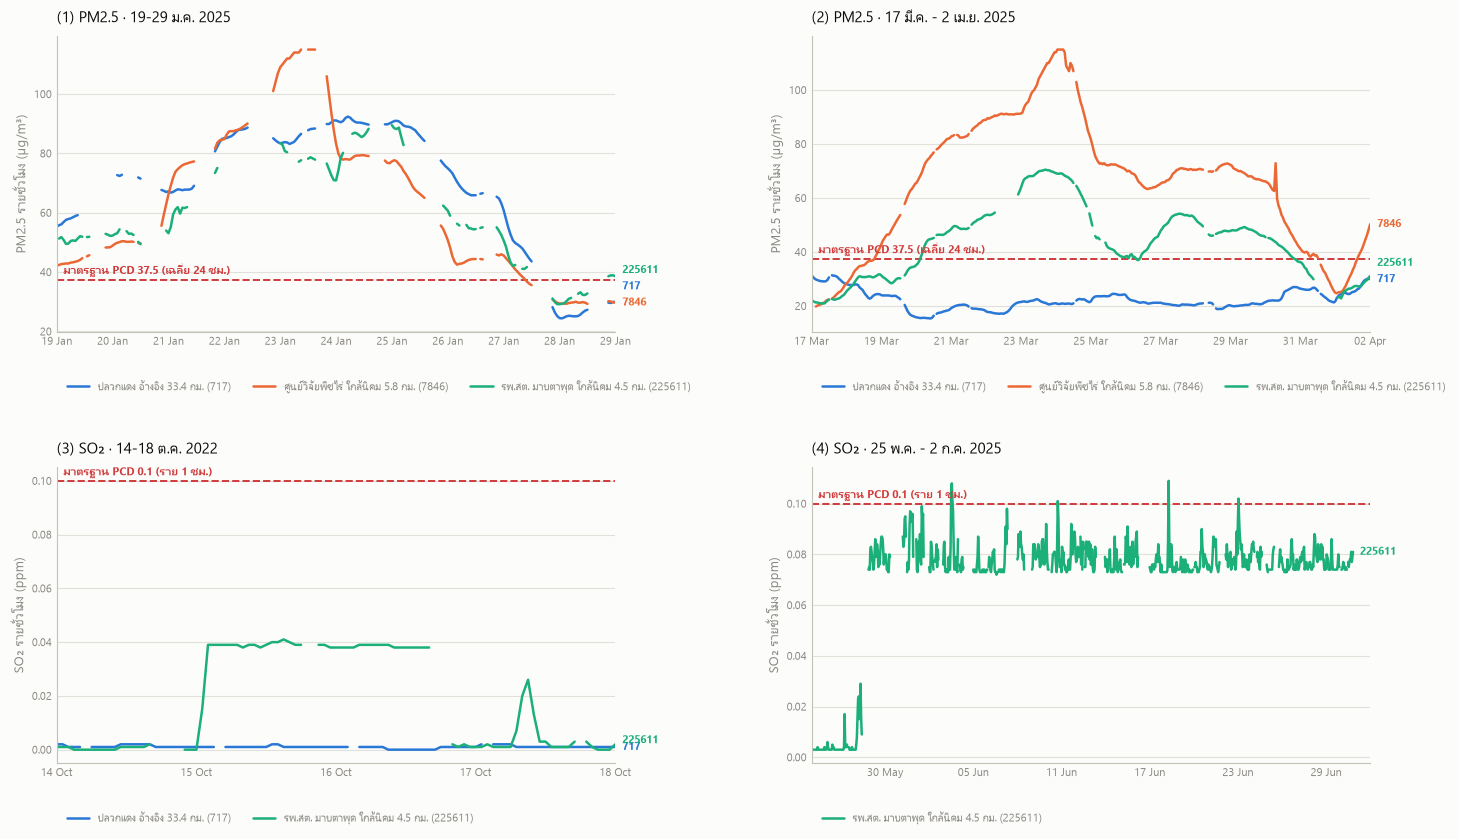

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ฟอนต์ที่รองรับภาษาไทย (มีมากับ Windows) ไม่งั้นตัวอักษรไทยจะกลายเป็นกล่องสี่เหลี่ยม
plt.rcParams["font.family"] = ["Leelawadee UI", "Tahoma", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_parquet("../data/processed/hourly_flagged.parquet")

# สีประจำสถานี กำหนดตายตัว ไม่เปลี่ยนตามกราฟ
STATION_COLOR = {717: "#2a78d6", 7846: "#eb6834", 225611: "#1baf7a"}
# พิกัดสถานีชุดเดียวกับ src/fetch_wind.py และจุดศูนย์กลางมาบตาพุดจาก src/fetch_data.py
MAPTAPHUT = (12.6833, 101.1333)
STATION_COORD = {717: (12.9738, 101.2129), 7846: (12.7352, 101.1356), 225611: (12.7087, 101.1660)}
STATION_NAME = {717: "ปลวกแดง อ้างอิง", 7846: "ศูนย์วิจัยพืชไร่ ใกล้นิคม", 225611: "รพ.สต. มาบตาพุด ใกล้นิคม"}

def km_from_maptaphut(lat, lon):
    """ระยะทางจากจุดศูนย์กลางมาบตาพุดถึงสถานี หน่วยกิโลเมตร"""
    p = np.pi / 180
    a = (np.sin((lat - MAPTAPHUT[0]) * p / 2) ** 2
         + np.cos(MAPTAPHUT[0] * p) * np.cos(lat * p) * np.sin((lon - MAPTAPHUT[1]) * p / 2) ** 2)
    return 2 * 6371 * np.arcsin(np.sqrt(a))

# ป้ายกราฟให้โค้ดคำนวณระยะเอง ไม่พิมพ์ตัวเลขลงไปตรง ๆ
STATION_LABEL = {sid: f"{STATION_NAME[sid]} {km_from_maptaphut(*STATION_COORD[sid]):.1f} กม. ({sid})"
                 for sid in STATION_NAME}
print(STATION_LABEL)
THRESHOLD = "#d03b3b"
GRID, AXIS, MUTED, INK = "#e1e0d9", "#c3c2b7", "#898781", "#0b0b0b"

CASES = [
    dict(p="pm25", s="2025-01-19", e="2025-01-29", std=37.5, std_note="เฉลี่ย 24 ชม.",
         title="(1) PM2.5 · 19-29 ม.ค. 2025"),
    dict(p="pm25", s="2025-03-17", e="2025-04-02", std=37.5, std_note="เฉลี่ย 24 ชม.",
         title="(2) PM2.5 · 17 มี.ค. - 2 เม.ย. 2025"),
    dict(p="so2", s="2022-10-14", e="2022-10-18", std=0.100, std_note="ราย 1 ชม.",
         title="(3) SO₂ · 14-18 ต.ค. 2022"),
    dict(p="so2", s="2025-05-25", e="2025-07-02", std=0.100, std_note="ราย 1 ชม.",
         title="(4) SO₂ · 25 พ.ค. - 2 ก.ค. 2025"),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
fig.patch.set_facecolor("#fcfcfb")

for ax, c in zip(axes.ravel(), CASES):
    p = c["p"]
    s_ts, e_ts = pd.Timestamp(c["s"], tz="UTC"), pd.Timestamp(c["e"], tz="UTC")
    ax.set_facecolor("#fcfcfb")
    endpoints = []

    for sid in [717, 7846, 225611]:
        sub = df[(df.station_id == sid) & (df.datetime_utc >= s_ts) & (df.datetime_utc <= e_ts)]
        if sub[p].notna().sum() == 0:
            continue
        # resample รายชั่วโมง เพื่อให้ช่วงที่ข้อมูลขาดกลายเป็นเส้นขาด ไม่ใช่เส้นตรงลากข้าม
        ser = sub.set_index("datetime_utc")[p].resample("1h").mean()
        ax.plot(ser.index, ser.values, lw=1.8, color=STATION_COLOR[sid],
                label=STATION_LABEL[sid], solid_capstyle="round")
        valid = ser.dropna()
        if len(valid):
            endpoints.append([valid.index[-1], valid.iloc[-1], str(sid), STATION_COLOR[sid]])

    # ป้ายชื่อที่ปลายเส้น พร้อมดันให้ไม่ทับกัน
    if endpoints:
        lo, hi = ax.get_ylim()
        min_gap = (hi - lo) * 0.055
        endpoints.sort(key=lambda r: r[1])
        for k in range(1, len(endpoints)):
            if endpoints[k][1] - endpoints[k - 1][1] < min_gap:
                endpoints[k][1] = endpoints[k - 1][1] + min_gap
        for x, y, lbl, col in endpoints:
            ax.annotate(lbl, xy=(x, y), xytext=(5, 0), textcoords="offset points",
                        fontsize=8, color=col, va="center", weight="bold")

    ax.axhline(c["std"], color=THRESHOLD, ls="--", lw=1.4, zorder=1)
    ax.annotate(f"มาตรฐาน PCD {c['std']} ({c['std_note']})", xy=(0.012, c["std"]),
                xycoords=("axes fraction", "data"), xytext=(0, 4), textcoords="offset points",
                fontsize=8, color=THRESHOLD, weight="bold")

    unit = "µg/m³" if p.startswith("pm") else "ppm"
    ax.set_ylabel(f"{'PM2.5' if p=='pm25' else 'SO₂'} รายชั่วโมง ({unit})", fontsize=9, color=MUTED)
    ax.set_title(c["title"], fontsize=11, color=INK, loc="left", pad=10)

    ax.grid(True, axis="y", color=GRID, lw=0.8, ls="-")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS); ax.spines[side].set_linewidth(0.8)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)

    span = max(1, (e_ts - s_ts).days // 6)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=span))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.set_xlim(s_ts, e_ts)
    ax.legend(fontsize=8, frameon=False, loc="upper left",
              bbox_to_anchor=(0, -0.13), ncol=3, labelcolor=MUTED)

plt.tight_layout(h_pad=3.2, w_pad=3)
plt.savefig("../reports/example_episodes.png", bbox_inches="tight", facecolor="#fcfcfb", dpi=130)
print("บันทึกกราฟแล้ว")

print("ความครบของข้อมูลในแต่ละแผง:")
for c in CASES:
    s_ts, e_ts = pd.Timestamp(c["s"], tz="UTC"), pd.Timestamp(c["e"], tz="UTC")
    tot = int((e_ts - s_ts).total_seconds() // 3600)
    w = df[(df.datetime_utc >= s_ts) & (df.datetime_utc <= e_ts)]
    parts = [f"{sid} {100*w[w.station_id==sid][c['p']].notna().sum()/tot:.0f}%"
             for sid in [717, 7846, 225611] if w[w.station_id == sid][c["p"]].notna().sum()]
    print(f'   {c["title"][:34]:<36} -> {", ".join(parts)}')


**วิธีอ่านกราฟ**

เส้นที่ขาดเป็นช่วง ๆ คือช่วงที่ไม่มีข้อมูล ไม่ใช่ค่าศูนย์ (ความครบของข้อมูลแต่ละแผงพิมพ์ไว้ในผลลัพธ์ด้านบน แผง 1 ครบเพียง 50-72% จึงขาดมากที่สุด) เส้นประแดงคือมาตรฐาน PCD ซึ่งของ PM2.5 เป็นค่าเฉลี่ย 24 ชั่วโมง จึงใช้เป็นเส้นอ้างอิงเท่านั้น ส่วนตัวที่ใช้ตัดสินจริงคือ `pm25_roll24`

**สิ่งที่แต่ละแผงแสดง**

1. ทั้งสามสถานีขึ้นและลงพร้อมกัน แม้สถานีอ้างอิงจะอยู่ห่างจากจุดศูนย์กลางมาบตาพุดถึง 33.4 กม. ขณะที่สองสถานีใกล้นิคมห่างเพียง 4.5 และ 5.8 กม. สอดคล้องกับปรากฏการณ์กว้างระดับภูมิภาค
2. สองสถานีใกล้นิคมขึ้นไปถึง 70-115 µg/m³ แต่สถานีอ้างอิงอยู่ที่ราว 20 ตลอด เป็นคนละรูปแบบกับแผง 1 ชัดเจน
3. SO₂ ขึ้นไปค้างที่ 0.039-0.041 นาน 1.5 วัน ซึ่งผิดปกติเพราะเหตุการณ์ SO₂ ส่วนใหญ่ยาว 1 ชั่วโมง สถานีอ้างอิงมีข้อมูลแต่ไม่ขึ้นตาม จึงตรวจสอบได้แต่ยังสรุปไม่ได้ กฎจึงไม่ติดป้ายให้
4. ค่ากระโดดจาก ~0.003 ไป ~0.077 แล้วค้างอยู่ทั้งเดือน ไม่มีสถานีอื่นวัด SO₂ ในช่วงนั้นเลยจึงตรวจสอบไม่ได้ เป็นเคสที่ถูกติดป้าย `unverifiable`

## 10. ข้อจำกัดที่พบตอนทำกราฟ: 26% ของ PM2.5 ประเมินตามมาตรฐานไม่ได้

ตอนวาดกราฟพบว่าเส้นค่าเฉลี่ย 24 ชม. ขาดหายเป็นช่วง ๆ จึงตรวจสอบย้อนกลับไปที่ข้อมูล

มาตรฐาน PM2.5 เป็นค่าเฉลี่ย 24 ชั่วโมง การจะคำนวณค่าเฉลี่ยที่ใช้อ้างอิงได้ ต้องมีข้อมูลครบอย่างน้อย 75% ของหน้าต่างนั้น (`min_periods=18` จาก 24 ชั่วโมง) ซึ่งเป็นเกณฑ์ความครบถ้วนที่ใช้กันเป็นมาตรฐานในงานคุณภาพอากาศ

ผลคือชั่วโมงที่ข้อมูลรอบ ๆ ไม่ครบ จะประเมินตามมาตรฐานไม่ได้เลย:

| สถานี | มีข้อมูล PM2.5 | ประเมินไม่ได้ |
|---|---|---|
| 717 | 33,558 ชม. | 6,918 (20.6%) |
| 7846 | 20,825 ชม. | 6,087 (29.2%) |
| 225611 | 29,517 ชม. | 8,667 (29.4%) |

รวม **21,672 ชั่วโมง (ราว 26% ของข้อมูล PM2.5)** ที่มีค่าวัดอยู่ แต่ประเมินเทียบมาตรฐาน 24 ชม. ไม่ได้ ในจำนวนนี้มี 1,718 ชั่วโมงที่ค่ารายชั่วโมงเกิน 37.5 µg/m³ อยู่แล้ว

**ผลต่อตัวเลขของเรา:** จำนวนเหตุการณ์ PM2.5 ที่รายงาน (188 เหตุการณ์) เป็นค่า**ต่ำกว่าความจริง** เพราะมีจุดบอดนี้อยู่ ไม่ใช่เพราะไม่มีมลพิษ แต่เพราะข้อมูลไม่ครบพอจะตัดสินตามมาตรฐาน

จึงคงเกณฑ์ข้อมูลครบ 75% (`min_periods=18`) ไว้ เพราะถ้าลดลง ค่าเฉลี่ยบางค่าจะมาจากข้อมูลไม่กี่ชั่วโมงและไม่ตรงนิยามของมาตรฐาน

## 11. ผลของช่องว่างข้อมูลต่อการวิเคราะห์แต่ละแบบ

ข้อมูลชุดนี้มีช่องว่างมาก จึงตรวจสอบว่ากระทบส่วนไหนบ้าง

**ความครบของข้อมูล ตลอดช่วงที่แต่ละสถานีเปิดใช้งาน**

| สถานี | SO₂ | PM2.5 |
|---|---|---|
| 717 (สถานีอ้างอิง) | 61.1% | 70.6% |
| 7846 | 22.2% | 51.5% |
| 225611 | 44.9% | 62.1% |

**ส่วนที่ช่องว่างไม่กระทบ**

- **baseline และ z-score** ปลอดภัยที่สุด เพราะคำนวณจากการกองข้อมูลข้ามปีมารวมกัน ไม่ต้องการความต่อเนื่อง ตรวจแล้วพบว่าทั้ง 216 กลุ่ม (สถานี × ฤดู × ชั่วโมง) มีข้อมูลอย่างน้อย 137 ชั่วโมง มัธยฐาน 364 ชั่วโมง และไม่มีกลุ่มใดต่ำกว่า 30 ชั่วโมง ซึ่งเพียงพอต่อการหาค่ากลางที่นิ่ง
- **local increment** คำนวณได้ 79-97% ของชั่วโมงที่สถานีใกล้นิคมมีข้อมูล (SO₂ ราว 80%, PM2.5 ราว 97%)

**ส่วนที่ช่องว่างกระทบ**

- **ค่าเฉลี่ย 24 ชม. ของ PM2.5** กระทบหนักสุด 26% ประเมินไม่ได้ (รายละเอียดในหัวข้อ 10)
- **จำนวนเหตุการณ์สูงเกินจริงเล็กน้อย** ถ้าเหตุการณ์จริงหนึ่งอันมีช่องว่างคั่นกลาง ระบบจะนับเป็นสองเหตุการณ์ ตรวจคู่เหตุการณ์ที่ห่างกันไม่เกิน 48 ชั่วโมงทั้งหมด 1,538 คู่ พบว่า **57 คู่ (2.3% ของเหตุการณ์ทั้งหมด)** มีช่วงคั่นที่ไม่มีข้อมูลเลย จึงอาจเป็นเหตุการณ์เดียวที่ถูกตัดขาด ส่วนอีก 1,481 คู่มีข้อมูลจริงที่เป็นค่าปกติคั่นอยู่ ซึ่งแยกถูกต้องแล้ว

**ผลต่อ Day 5 (พยากรณ์)**

โมเดลพยากรณ์ต้องใช้ค่าย้อนหลัง (lag features) ซึ่งช่องว่างจะทำให้บางแถวใช้ไม่ได้ ตรวจแล้วพบว่าถ้าต้องการ lag ที่ t-1, t-2, t-3 และ t-24 ครบ จะเหลือข้อมูลเทรนดังนี้

| สถานี/สาร | ชั่วโมงที่เทรนได้ |
|---|---|
| 225611 SO₂ | 10,728 (50% ของที่มี) |
| 225611 PM2.5 | 17,517 (59%) |
| 717 PM2.5 | 23,490 (70%) |

ถือว่าเพียงพอสำหรับ LightGBM ซึ่งต้องการเพียงแถวที่ฟีเจอร์ครบ ไม่ต้องการอนุกรมต่อเนื่อง

แต่**ช่วงข้อมูลต่อเนื่องยาวที่สุดมีเพียง 350 ชั่วโมง** (ราว 2 สัปดาห์) และไม่มีช่วงใดยาวเกิน 30 วันเลย ดังนั้นโมเดลที่ต้องการลำดับต่อเนื่องยาว เช่น LSTM จะทำได้ยาก

## สรุปผล Day 3

**ผลลัพธ์**
- `data/processed/episodes.csv` จำนวน **2,451 เหตุการณ์**
- `data/processed/hourly_with_increment.parquet` พร้อมคอลัมน์ local increment
- `reports/example_episodes.png` กราฟตัวอย่าง 4 เหตุการณ์

**วิธีที่ใช้**
1. **MAD floor** ใส่พื้นที่ความละเอียดเครื่องวัด เพื่อให้ z-score ใช้ได้กับกลุ่มที่ค่าส่วนใหญ่เป็น 0 (23.4% ของข้อมูล SO₂)
2. **ใช้ z ≥ 5 ร่วมกับมาตรฐาน PCD** เพราะ z-score อย่างเดียวพลาดชั่วโมงที่ PM2.5 เกินมาตรฐานไป 4,445 ชั่วโมง เนื่องจากหมอกควันฤดูแล้งถูกนับเป็น "ปกติของฤดูนั้น"
3. **ติดป้าย ไม่ลบทิ้ง** เหตุการณ์ที่สงสัยว่าเซนเซอร์ผิดปกติติดป้าย `unverifiable` (7 เหตุการณ์ = 0.29%) เพราะไม่มีสถานีอื่นวัดสารเดียวกันในช่วงนั้นจึงตรวจสอบไม่ได้